# 01 – Sensor trust: propulsion

**Question:** which propulsion sensors can we trust, and when? Shaft power drives every fouling estimate, so this comes first.

**Signals:** `shaft_kw`, `shaft_rpm`, `shaft_torque_nm`, `thrust_kn`, `shaft_kwh`, `shaft_revs` (torquemeter); `fo_kgh` (fuel flow); `me_rpm`, `me_load_pct`, `me_scav_bar`, `me_tc_rpm_tr` (engine). `sog_kn`, `stw_kn` and `heading_deg` are only used for context.

**Rules** (see `README.md`): nothing is fixed here, only found, dated and counted. Limits come from `physical_limits.md`. Every check is judged per operating mode (port, anchor, sailing).

**Before running:** `python src/load_raw.py` once. The first run builds a cache (about 1 min).

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

sys.path.insert(0, os.path.join("..", "..", "src"))
import trust as T

SIG = ["shaft_kw", "shaft_rpm", "shaft_torque_nm", "thrust_kn", "shaft_kwh", "shaft_revs", "fo_kgh",
       "me_rpm", "me_load_pct", "me_scav_bar", "me_tc_rpm_tr", "sog_kn", "stw_kn", "heading_deg"]
PROP = SIG[:11]
w = T.load_wide(SIG, name="propulsion")
mode = T.operating_mode(w)
F = T.Findings("01_propulsion")

BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, MUTED, GRID = "#1f1f1e", "#6b6a64", "#e6e5e0"
plt.rcParams.update({"axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
                     "grid.linewidth": 0.6, "axes.axisbelow": True, "font.size": 9, "axes.titlesize": 10})
pd.set_option("display.width", 200, "display.max_columns", 30)

def hours(n):
    return n * 15 / 3600

def month_axis(ax):
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))

print(f"{len(w):,} moments (15 s), {w.index.min()} to {w.index.max()}")
print("hours per operating mode:")
print(hours(mode.value_counts()).round(0).to_string())

2,103,486 moments (15 s), 2024-01-01 00:00:00 to 2025-01-31 23:56:45
hours per operating mode:
sailing                    6985.0
port                        937.0
anchor                      744.0
unknown                      98.0
port, propeller turning       1.0


**Engine running** is defined from the *engine* sensor (`me_rpm` > 30), not from the torquemeter, so that a torquemeter fault cannot hide itself. Most checks below look at moments where the ship is **sailing with the engine running**.

In [2]:
running = (mode == "sailing") & (w.me_rpm > 30)
print(f"sailing with engine running: {hours(running.sum()):,.0f} h")

sailing with engine running: 6,039 h


## Overview: the torquemeter through the year

Hourly medians while sailing with the engine running. Shaded bands mark the faults found below:
- **grey:** torquemeter reads 0 although the engine turns (dropout, §2)
- **orange:** torquemeter reads negative although the engine runs ahead (sign fault, §2)
- **dashed lines:** steps in fuel per kWh (§6d)

Panel 2 compares shaft rpm (torquemeter, thin blue) with engine rpm (independent sensor, thick grey underneath): they should lie on top of each other. Panel 4 is power ÷ rpm³, which only moves slowly with loading and fouling; a sudden drop is a sensor problem.

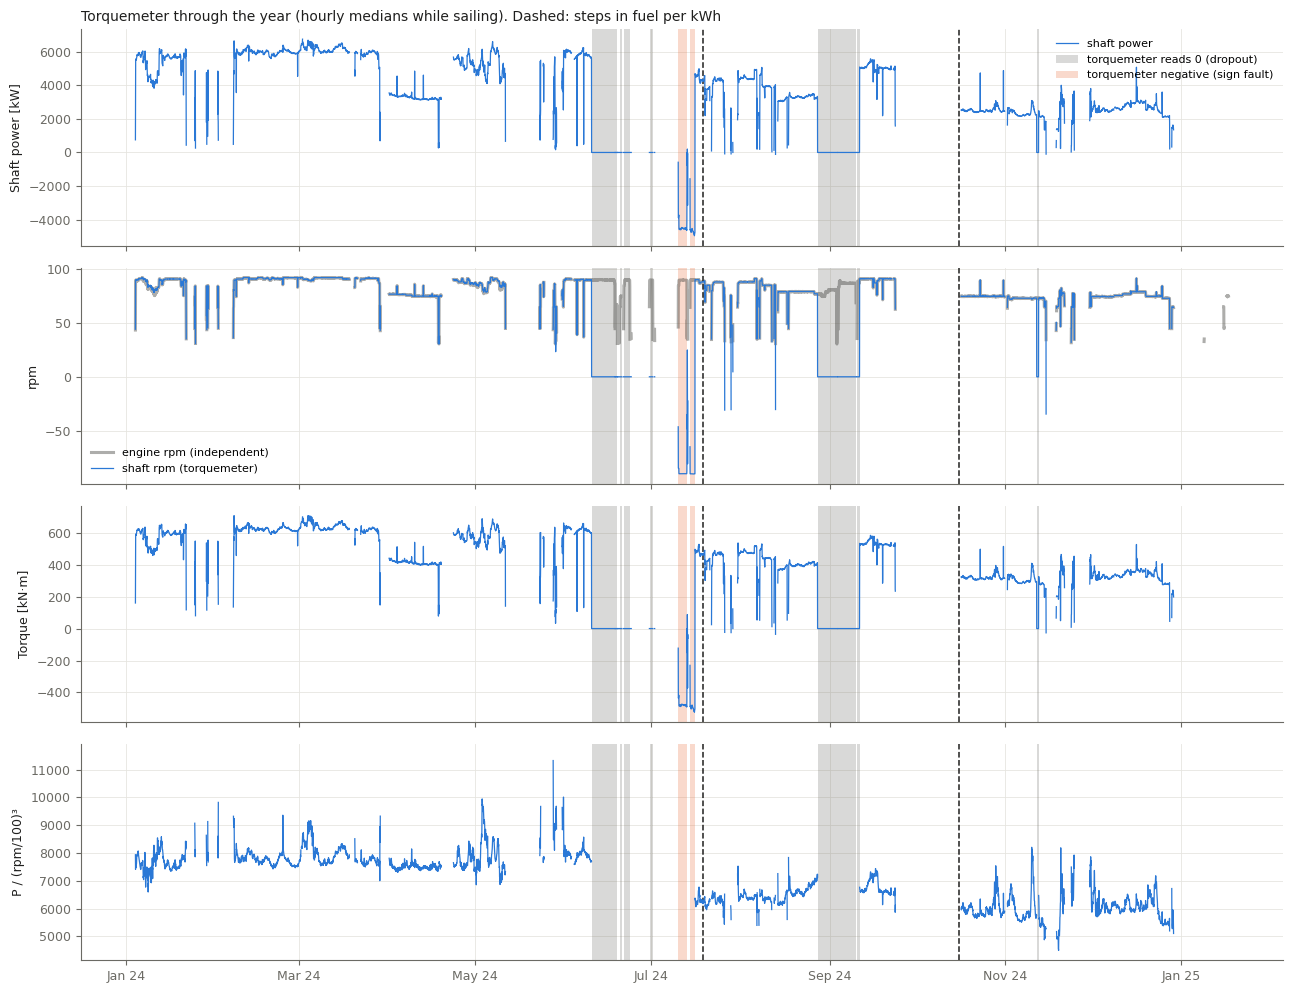

In [3]:
tm_zero_o = (w.me_rpm > 50) & (w.shaft_rpm.abs() < 1) & (w.shaft_kw.abs() < 50) & (w.shaft_torque_nm.abs() < 5)
sign_fault_o = (w.shaft_rpm < -5) & (w.me_rpm > 5)
h = w.loc[running].resample("1h").median()
kk = (w.shaft_kw / (w.shaft_rpm / 100) ** 3).where(running & (w.shaft_rpm > 60) & (w.shaft_kw > 1000)).resample("1h").median()
zero_h = tm_zero_o.resample("1h").mean() > 0.5
sign_h = sign_fault_o.resample("1h").mean() > 0.5
sfoc_o = T.daily((1000 * w.fo_kgh / w.shaft_kw).where(running & (w.shaft_kw > 2000) & (w.fo_kgh > 200)), "median")
steps_o = T.find_steps(sfoc_o)

fig, axes = plt.subplots(4, 1, figsize=(13, 10), sharex=True)
panels = [
    ("Shaft power [kW]", [(h.shaft_kw, BLUE, "shaft power")]),
    ("rpm", [(h.me_rpm, "#4a4a46", "engine rpm (independent)"), (h.shaft_rpm, BLUE, "shaft rpm (torquemeter)")]),
    ("Torque [kN·m]", [(h.shaft_torque_nm, BLUE, "torque")]),
    ("P / (rpm/100)³", [(kk, BLUE, "power ÷ rpm³")]),
]
for ax, (ylab, series) in zip(axes, panels):
    for ser, col, lab in series:
        thick = col == "#4a4a46"
        ax.plot(ser.index, ser, color=col, lw=2.2 if thick else 0.9, alpha=0.45 if thick else 1, label=lab,
                zorder=2 if thick else 3)
    ax.set_ylabel(ylab)
    if len(series) > 1:
        ax.legend(frameon=False, loc="lower left", fontsize=8)
# shade fault periods (hourly runs)
def shade(mask, color, label):
    m = mask.astype(int)
    starts = m.index[(m.diff() == 1) | ((m.index == m.index[0]) & (m == 1))]
    ends = m.index[(m.diff() == -1)]
    for i_, st_ in enumerate(starts):
        en_ = ends[ends > st_].min() if (ends > st_).any() else m.index[-1]
        for ax in axes:
            ax.axvspan(st_, en_, color=color, alpha=0.25, lw=0, label=label if (i_ == 0 and ax is axes[0]) else None)
shade(zero_h, MUTED, "torquemeter reads 0 (dropout)")
shade(sign_h, ORANGE, "torquemeter negative (sign fault)")
for _, s_ in steps_o.iloc[1:].iterrows():
    for ax in axes:
        ax.axvline(pd.Timestamp(s_["from"]), color=INK, ls="--", lw=1.1)
axes[0].legend(frameon=False, loc="upper right", fontsize=8)
axes[0].set_title("Torquemeter through the year (hourly medians while sailing). Dashed: steps in fuel per kWh",
                  loc="left", color=INK)
month_axis(axes[-1]); fig.tight_layout(); plt.show()

## 1. Missing data

Share of moments per month where each signal has a value. The engine and torquemeter signals should be present whenever the logger runs.

In [4]:
present = w[PROP].notna().groupby(w.index.to_period("M")).mean() * 100
print("% of logged moments with a value")
display(present.round(1))

g = T.runs(w[PROP].isna().all(axis=1) & w.sog_kn.notna())
print(f"Moments where ALL propulsion signals are missing but GPS works: {hours(g.readings.sum()):,.0f} h in {len(g)} periods")
display(g.sort_values("hours", ascending=False).head(5).round(1))

% of logged moments with a value


,shaft_kw,shaft_rpm,shaft_torque_nm,thrust_kn,shaft_kwh,shaft_revs,fo_kgh,me_rpm,me_load_pct,me_scav_bar,me_tc_rpm_tr
time,,,,,,,,,,,
2024-01,93.4,93.4,93.4,93.4,93.4,93.4,93.4,93.4,93.4,93.4,93.4
2024-02,99.7,99.7,99.7,99.7,99.7,99.7,99.7,99.8,99.8,99.8,99.8
2024-03,83.8,83.8,83.8,83.8,83.8,83.8,83.8,83.7,84.0,84.0,84.0
2024-04,99.1,99.0,99.0,99.1,99.1,99.1,99.1,84.7,99.1,99.1,99.1
2024-05,95.6,95.6,95.6,95.6,95.6,95.6,95.6,95.6,95.6,95.6,95.6
2024-06,94.1,94.2,94.2,94.2,94.1,94.2,94.1,93.8,94.2,94.2,94.2
2024-07,99.6,99.6,99.6,99.6,99.6,99.6,99.6,99.6,99.6,99.6,99.6
2024-08,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
2024-09,97.1,97.1,97.1,97.1,97.1,97.1,97.1,97.1,97.1,97.1,97.1


Moments where ALL propulsion signals are missing but GPS works: 409 h in 2157 periods


,start,end,readings,hours
3,2024-01-22 13:49:15,2024-01-24 14:38:30,11718,48.8
113,2024-10-04 07:00:15,2024-10-06 06:49:45,11479,47.8
82,2024-03-30 09:51:00,2024-04-01 06:00:00,10597,44.2
80,2024-03-21 06:09:30,2024-03-22 09:11:30,6487,27.0
90,2024-06-03 11:14:30,2024-06-04 11:14:00,5759,24.0


## 2. Fake values: zeros where a real value should be

| Check | Why it is impossible |
|---|---|
| Torquemeter reads 0 (rpm, power and torque) while the **engine** turns above 50 rpm | the engine drives the shaft directly |
| Shaft turns above 50 rpm but engine rpm is 0 | same |
| Fuel flow above 0 while engine and shaft stand still | a stopped engine burns no fuel |
| Shaft rpm **negative** while the **engine** runs ahead | the shaft cannot turn the other way than the engine |

In [5]:
tm_zero = (w.me_rpm > 50) & (w.shaft_rpm.abs() < 1) & (w.shaft_kw.abs() < 50) & (w.shaft_torque_nm.abs() < 5)
me_zero = (w.shaft_rpm > 50) & (w.me_rpm.abs() < 1)
fuel_stopped = (w.me_rpm.abs() < 1) & (w.shaft_rpm.abs() < 1) & (w.fo_kgh > 50)
sign_fault = (w.shaft_rpm < -5) & (w.me_rpm > 5)        # torquemeter says astern, engine says ahead
astern = (w.shaft_rpm < -5) & (w.me_rpm < -5)           # real astern: both agree

for name, m in [("torquemeter 0 while engine turns", tm_zero), ("engine rpm 0 while shaft turns", me_zero),
                ("fuel flow while engine stopped", fuel_stopped), ("shaft negative while engine ahead", sign_fault),
                ("real astern (engine and shaft both negative)", astern)]:
    print(f"{name}: {hours(m.sum()):,.0f} h ({m.sum():,} moments)")

r = T.runs(tm_zero)
print(f"\nTorquemeter at 0 while engine turns: {len(r)} periods. Longest:")
display(r.sort_values("hours", ascending=False).head(8).round(1))
print("Conditions during these moments (medians):")
print(w.loc[tm_zero, ["me_rpm", "fo_kgh", "me_load_pct", "sog_kn", "stw_kn"]].median().round(1).to_string())
print("\nhours per month:")
print(hours(tm_zero.groupby(w.index.to_period("M")).sum()).round(0).loc[lambda x: x > 0].to_string())

torquemeter 0 while engine turns: 656 h (157,494 moments)
engine rpm 0 while shaft turns: 0 h (32 moments)
fuel flow while engine stopped: 759 h (182,186 moments)
shaft negative while engine ahead: 123 h (29,415 moments)
real astern (engine and shaft both negative): 3 h (722 moments)

Torquemeter at 0 while engine turns: 44 periods. Longest:


,start,end,readings,hours
34,2024-08-27 20:26:15,2024-09-03 11:43:45,38231,159.3
37,2024-09-04 01:09:00,2024-09-09 13:10:45,31688,132.0
3,2024-06-10 10:40:45,2024-06-13 03:34:45,15577,64.9
8,2024-06-15 17:25:45,2024-06-17 11:34:00,10114,42.1
7,2024-06-14 10:51:30,2024-06-15 17:25:00,7335,30.6
18,2024-06-22 12:11:30,2024-06-23 17:59:00,7151,29.8
17,2024-06-21 13:56:15,2024-06-22 12:10:45,5339,22.2
10,2024-06-17 11:49:30,2024-06-18 09:37:15,5232,21.8


Conditions during these moments (medians):


me_rpm           87.5
fo_kgh         1126.0
me_load_pct      49.3
sog_kn           10.7
stw_kn           11.5

hours per month:


time
2024-06    293.0
2024-07     17.0
2024-08    100.0
2024-09    230.0
2024-11     16.0
Freq: M


In [6]:
sf_days = sign_fault.groupby(w.index.normalize()).sum().loc[lambda x: x > 0]
print(f"Shaft negative while engine ahead: {len(sf_days)} days, median SOG {w.loc[sign_fault, 'sog_kn'].median():.1f} kn, "
      f"median shaft rpm {w.loc[sign_fault, 'shaft_rpm'].median():.0f}, engine rpm {w.loc[sign_fault, 'me_rpm'].median():.0f}")
print("hours per month:"); print(hours(sign_fault.groupby(w.index.to_period("M")).sum()).round(1).loc[lambda x: x > 0].to_string())
print(f"Real astern: {hours(astern.sum()):.1f} h, median SOG {w.loc[astern, 'sog_kn'].median():.1f} kn")

fs = w.loc[fuel_stopped]
print(f"Fuel flow while stopped: median {fs.fo_kgh.median():.0f} kg/h, p95 {fs.fo_kgh.quantile(.95):.0f} kg/h; "
      f"operating mode: {hours(mode[fuel_stopped].value_counts()).round(0).to_dict()}")

F.add("`shaft_rpm`, `shaft_kw`, `shaft_torque_nm`", "mainly 10–17 Jun and 27 Aug – 9 Sep 2024", "missing / gap",
      f"Torquemeter reads exactly 0 while the ship sails (median {w.loc[tm_zero,'sog_kn'].median():.1f} kn) with the engine "
      f"at {w.loc[tm_zero,'me_rpm'].median():.0f} rpm and {w.loc[tm_zero,'fo_kgh'].median():.0f} kg/h fuel: a dropout written as 0",
      "§2", f"{hours(tm_zero.sum()):,.0f} h in {len(r)} periods",
      "Zero power while sailing; overlaps the end of the reference period (June)",
      "Set to NaN; never treat as real power")
F.add("`shaft_rpm`, `shaft_kw`, `shaft_torque_nm`", f"{len(sf_days)} days, {sf_days.index.min().date()} – {sf_days.index.max().date()} (most in 10–16 Jul)",
      "sign or unit",
      f"Torquemeter reports astern (negative rpm, power, torque) while the engine runs ahead and the ship sails at "
      f"{w.loc[sign_fault, 'sog_kn'].median():.1f} kn. Only {astern.sum():,} moments are real astern (engine also astern)",
      "§2", f"{sign_fault.sum():,} moments, {hours(sign_fault.sum()):.0f} h",
      "abs() would be right here but wrong for real astern; 'astern' counts are inflated",
      "Flip the sign only where the engine runs ahead; keep real astern")
F.add("`fo_kgh`", "port / anchor stays", "stuck or placeholder value",
      f"Fuel flow {fs.fo_kgh.median():.0f} kg/h (median) while engine and shaft stand still",
      "§2", f"{hours(fuel_stopped.sum()):,.0f} h", "Counted as consumption if summed",
      "Use fuel only when the engine turns; ask what the meter measures")

Shaft negative while engine ahead: 53 days, median SOG 13.5 kn, median shaft rpm -90, engine rpm 90
hours per month:
time
2024-02      0.1
2024-05      0.1
2024-07    118.0
2024-08      1.5
2024-09      0.5
2024-10      0.1
2024-11      1.8
2024-12      0.4
Freq: M
Real astern: 3.0 h, median SOG 1.2 kn
Fuel flow while stopped: median 303 kg/h, p95 399 kg/h; operating mode: {'port': 307.0, 'anchor': 258.0, 'sailing': 194.0, 'port, propeller turning': 0.0, 'unknown': 0.0}


## 3. Stuck values while sailing

Runs of 30 min or more where a signal keeps exactly the same value while the ship sails with the engine running. A real sensor always moves a little at sea.

In [7]:
rows, stuck_by = [], {}
for s in PROP:
    st = stuck_by[s] = T.stuck_runs(w[s], running, min_hours=0.5)
    if len(st):
        top = st.groupby("value").hours.sum().sort_values(ascending=False)
        rows.append({"signal": s, "runs": len(st), "hours": st.hours.sum(), "longest_h": st.hours.max(),
                     "most_common_stuck_value": top.index[0], "hours_at_that_value": top.iloc[0]})
stuck = pd.DataFrame(rows).set_index("signal").round(1) if rows else pd.DataFrame()
stuck

,runs,hours,longest_h,most_common_stuck_value,hours_at_that_value
signal,,,,,
shaft_kw,16,664.2,168.9,0.000000e+00,664.2
shaft_rpm,16,664.2,168.9,0.000000e+00,664.2
shaft_torque_nm,16,664.2,168.9,0.000000e+00,664.2
thrust_kn,16,664.2,168.9,0.000000e+00,664.2
shaft_kwh,21,781.4,168.9,1.012312e+08,331.2
shaft_revs,16,663.9,168.9,6.227289e+09,331.2


## 4. Physical range

Readings above the *check* and *hard* limits from `physical_limits.md` (for rpm also below the astern limits).

In [8]:
rows = []
for s, (chk, hard) in T.LIMITS.items():
    if s not in w:
        continue
    v = w[s].dropna()
    lo_chk, lo_hard = T.LIMITS_LOW.get(s, (-np.inf, -np.inf))
    rows.append({"signal": s, "readings": len(v), "max": v.max(), "min": v.min(),
                 "above_check": int((v > chk).sum()), "above_hard": int((v > hard).sum()),
                 "below_check": int((v < lo_chk).sum()), "below_hard": int((v < lo_hard).sum())})
rng = pd.DataFrame(rows).set_index("signal")
display(rng.round(1))
fuel_hi = w.fo_kgh > T.LIMITS["fo_kgh"][1]
fh = fuel_hi.groupby(w.index.normalize()).sum().loc[lambda x: x > 0]
print("fuel above hard limit, readings per day:", {str(k_.date()): int(v_) for k_, v_ in fh.items()},
      "| mode:", mode[fuel_hi].value_counts().to_dict())
F.add("`fo_kgh`", ", ".join(str(k_.date()) for k_ in fh.index), "out of range",
      f"Fuel flow up to {w.fo_kgh.max():,.0f} kg/h, above the {T.LIMITS['fo_kgh'][1]:,} kg/h hard limit "
      f"(engine max ≈ 1,710 kg/h); mostly during the late-June port stay", "§4", f"{int(fuel_hi.sum())} readings",
      "Fuel spikes distort daily sums", "Set to NaN")

,readings,max,min,above_check,above_hard,below_check,below_hard
signal,,,,,,,
shaft_rpm,1907811,103.6,-535.5,0,0,21437,2
me_rpm,1965159,108.9,-68.3,14,0,0,0
shaft_kw,1907776,7464.0,-24757.0,0,0,2,2
shaft_torque_nm,1907810,772.1,-551.7,0,0,0,0
fo_kgh,1907778,4153.0,0.0,57,47,0,0
me_load_pct,1908484,60.0,0.0,0,0,0,0
stw_kn,2057890,14.9,-3.6,0,0,0,0
sog_kn,2080048,15.3,0.0,0,0,0,0


fuel above hard limit, readings per day: {'2024-01-29': 1, '2024-02-05': 2, '2024-05-20': 6, '2024-06-27': 21, '2024-06-29': 15, '2024-12-24': 2} | mode: {'port': 38, 'anchor': 7, 'sailing': 2}


## 4b. Outliers: distributions

Three views, all while **sailing with the engine running**, leaving out the torquemeter zeros and sign faults already found in §2 (otherwise they would distort the bounds):

1. **Histogram per signal** with the **physical limits** (orange: check, red: hard) and **robust statistical bounds** (dashed: median ± 5 × MAD, scaled to a standard deviation). MAD is used instead of the standard deviation because outliers cannot inflate it.
2. **Box plots per month:** how each distribution moves through the year.
3. **Context outliers:** values that are normal on their own but impossible together (power far from the power–rpm curve).

A statistical outlier is **not automatically a fault**: a storm gives real high power. These figures flag; physics and the cross-checks decide.

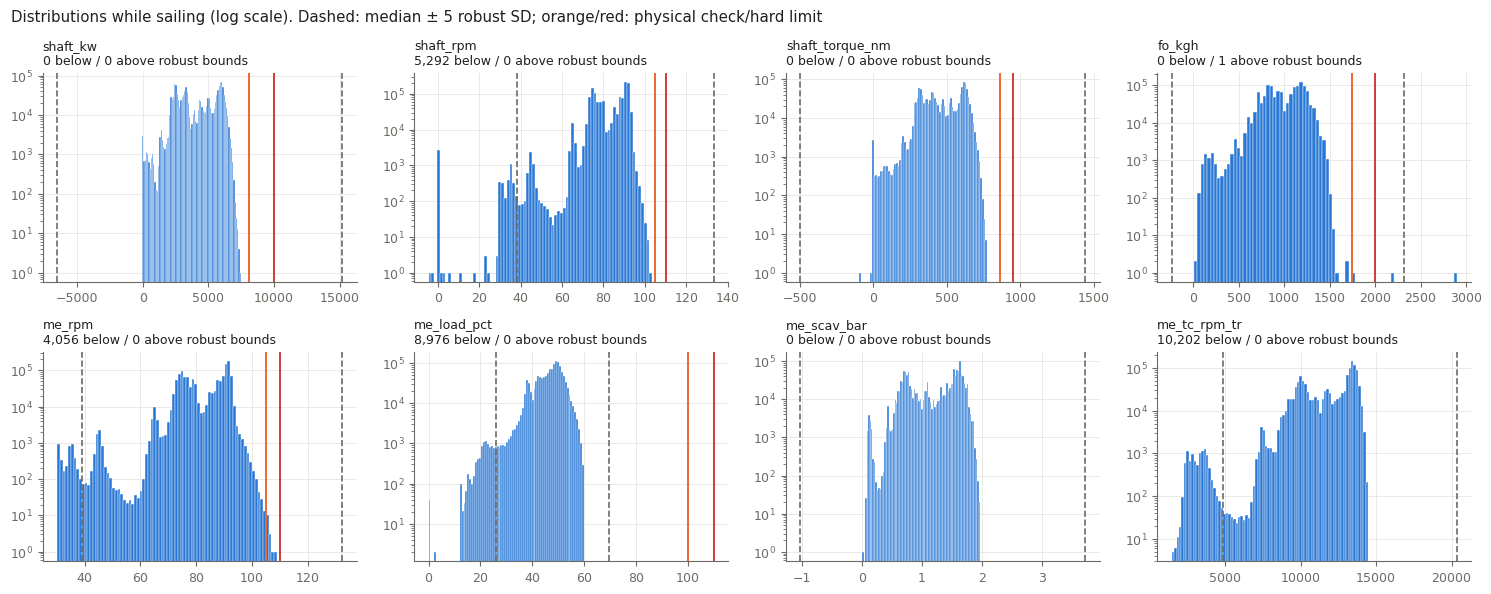

,median,robust_sd,lower_bound,upper_bound,below,above,share_%
signal,,,,,,,
shaft_kw,4333.23,2171.36,-6523.56,15190.01,0,0,0.00
shaft_rpm,85.71,9.52,38.13,133.28,5292,0,0.42
shaft_torque_nm,472.15,193.86,-497.15,1441.45,0,0,0.00
fo_kgh,1038.00,255.01,-237.04,2313.04,0,1,0.00
me_rpm,85.60,9.34,38.90,132.30,4056,0,0.32
me_load_pct,47.80,4.37,25.93,69.66,8976,0,0.71
me_scav_bar,1.34,0.47,-1.03,3.71,0,0,0.00
me_tc_rpm_tr,12602.23,1549.65,4853.97,20350.50,10202,0,0.81


In [9]:
OUT_SIG = ["shaft_kw", "shaft_rpm", "shaft_torque_nm", "fo_kgh", "me_rpm", "me_load_pct", "me_scav_bar", "me_tc_rpm_tr"]
RED = "#d03b3b"
rows = []
fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for ax, s in zip(axes.flat, OUT_SIG):
    v = w.loc[running & ~tm_zero & ~sign_fault, s].dropna()     # known faults are already flagged
    med = v.median(); mad = 1.4826 * (v - med).abs().median()
    lo, hi = med - 5 * mad, med + 5 * mad
    ax.hist(v, bins=80, color=BLUE, edgecolor="white", linewidth=0.3, log=True)
    ax.axvline(lo, color=MUTED, ls="--", lw=1.2); ax.axvline(hi, color=MUTED, ls="--", lw=1.2)
    if s in T.LIMITS:
        ax.axvline(T.LIMITS[s][0], color=ORANGE, lw=1.4); ax.axvline(T.LIMITS[s][1], color=RED, lw=1.4)
    n_lo, n_hi = int((v < lo).sum()), int((v > hi).sum())
    ax.set_title(f"{s}\n{n_lo:,} below / {n_hi:,} above robust bounds", loc="left", color=INK, fontsize=9)
    rows.append({"signal": s, "median": med, "robust_sd": mad, "lower_bound": lo, "upper_bound": hi,
                 "below": n_lo, "above": n_hi, "share_%": 100 * (n_lo + n_hi) / len(v)})
fig.suptitle("Distributions while sailing (log scale). Dashed: median ± 5 robust SD; orange/red: physical check/hard limit",
             x=0.01, ha="left", color=INK)
fig.tight_layout(); plt.show()
pd.DataFrame(rows).set_index("signal").round(2)

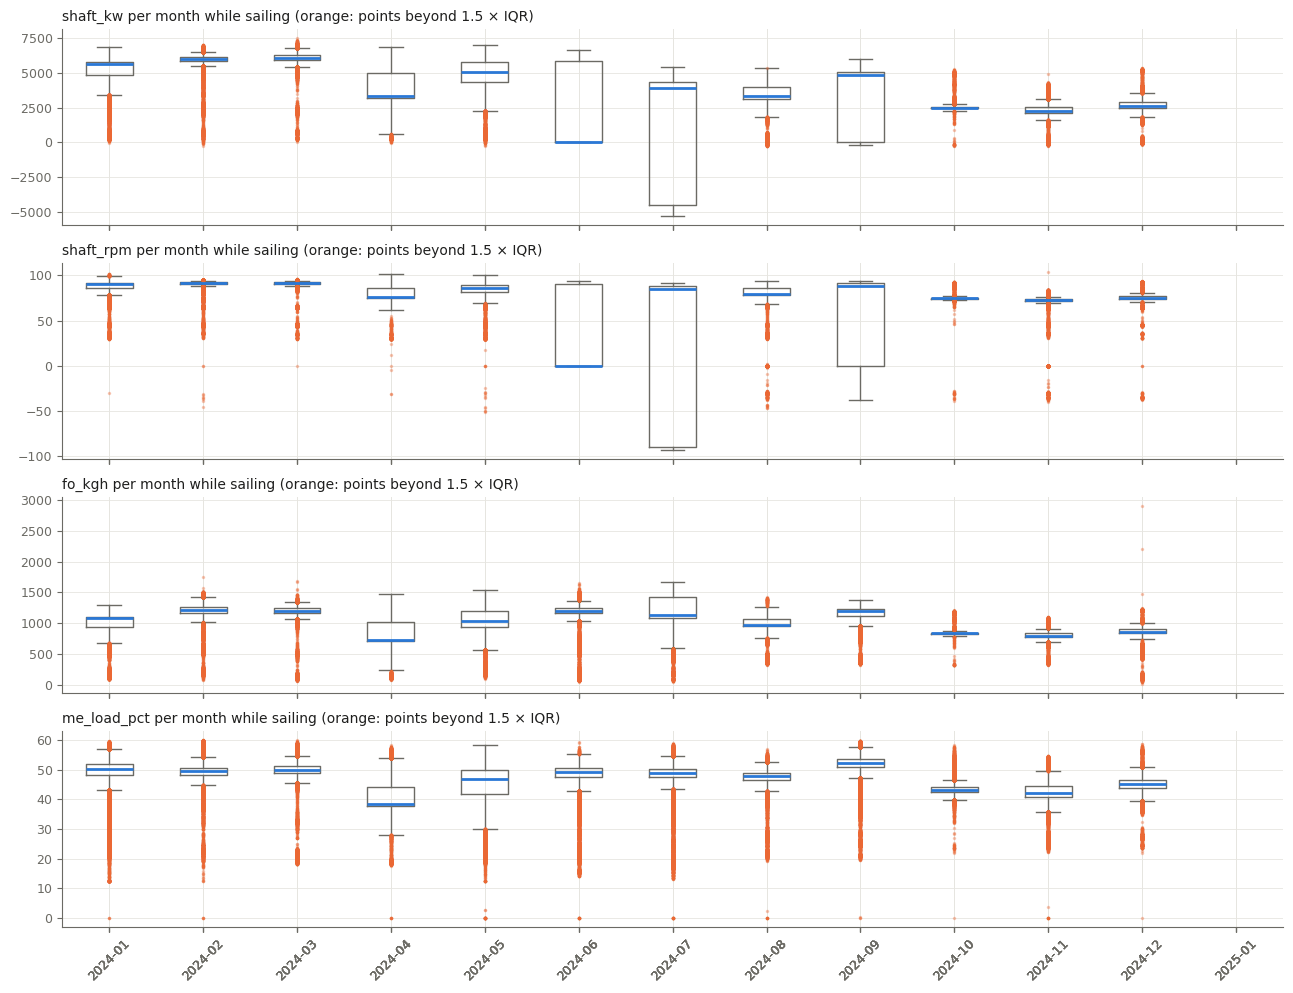

In [10]:
BOX_SIG = ["shaft_kw", "shaft_rpm", "fo_kgh", "me_load_pct"]
mon = w.index.to_period("M")
fig, axes = plt.subplots(len(BOX_SIG), 1, figsize=(13, 10), sharex=True)
for ax, s in zip(axes, BOX_SIG):
    data = w.loc[running, s].groupby(mon[running])
    labels = [str(m) for m, _ in data]
    ax.boxplot([g.dropna().values for _, g in data], tick_labels=labels, showfliers=True, flierprops=dict(markersize=1.5,
               markerfacecolor=ORANGE, markeredgecolor=ORANGE, alpha=0.3), medianprops=dict(color=BLUE, linewidth=2),
               boxprops=dict(color=MUTED), whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED))
    ax.set_title(f"{s} per month while sailing (orange: points beyond 1.5 × IQR)", loc="left", color=INK)
axes[-1].tick_params(axis="x", rotation=45)
fig.tight_layout(); plt.show()

power–rpm fit before July: P ∝ rpm^2.97; context outliers (|residual| > 5 robust SD): 264 moments
context outliers per month:
time
2024-01    233
2024-04      1
2024-05     30
Freq: M


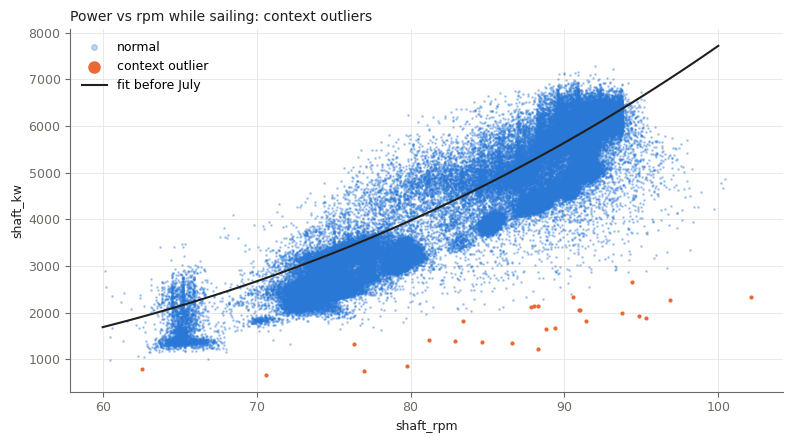

In [11]:
ok = running & (w.shaft_rpm > 60) & (w.shaft_kw > 500) & (w.index < "2024-07-10")
x = np.log(w.loc[ok, "shaft_rpm"]); y = np.log(w.loc[ok, "shaft_kw"])
b, a = np.polyfit(x, y, 1)
fit_all = running & (w.shaft_rpm > 60) & (w.shaft_kw > 500)
sub = w.loc[fit_all]
resid = pd.Series(np.log(sub.shaft_kw) - (a + b * np.log(sub.shaft_rpm)), index=sub.index).reindex(w.index)
rmed = resid.median(); rmad = 1.4826 * (resid - rmed).abs().median()
ctx = (resid - rmed).abs() > 5 * rmad
print(f"power–rpm fit before July: P ∝ rpm^{b:.2f}; context outliers (|residual| > 5 robust SD): {int(ctx.sum()):,} moments")
print("context outliers per month:"); print(ctx.groupby(w.index.to_period("M")).sum().loc[lambda s_: s_ > 0].to_string())

sample = w.loc[fit_all, ["shaft_rpm", "shaft_kw"]].sample(min(int(fit_all.sum()), 150_000), random_state=0)
out = sample[ctx.reindex(sample.index, fill_value=False)]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(sample.shaft_rpm, sample.shaft_kw, s=1, color=BLUE, alpha=0.3, rasterized=True, label="normal")
ax.scatter(out.shaft_rpm, out.shaft_kw, s=4, color=ORANGE, label="context outlier")
rr_ = np.linspace(60, 100, 50); ax.plot(rr_, np.exp(a + b * np.log(rr_)), color=INK, lw=1.5, label="fit before July")
ax.set_xlabel("shaft_rpm"); ax.set_ylabel("shaft_kw"); ax.legend(frameon=False, markerscale=4)
ax.set_title("Power vs rpm while sailing: context outliers", loc="left", color=INK)
fig.tight_layout(); plt.show()

## 5. Spikes

Changes between two consecutive readings (15 s apart) that are too large for a 75,000 t ship while sailing. Thresholds are deliberately generous.

In [12]:
JUMP = {"shaft_rpm": 10, "me_rpm": 10, "shaft_kw": 1500, "shaft_torque_nm": 150, "fo_kgh": 400, "me_load_pct": 15}
step_ok = w.index.to_series().diff() == pd.Timedelta("15s")
rows = []
for s, lim in JUMP.items():
    d = w[s].diff().abs()
    m = (d > lim) & step_ok & running & running.shift(1, fill_value=False)
    days = m.groupby(w.index.normalize()).sum()
    rows.append({"signal": s, "threshold": lim, "spikes": int(m.sum()), "days_with_spikes": int((days > 0).sum()),
                 "worst_day": days.idxmax().date() if m.any() else None})
pd.DataFrame(rows).set_index("signal")

,threshold,spikes,days_with_spikes,worst_day
signal,,,,
shaft_rpm,10,6584,107,2024-01-10
me_rpm,10,11295,89,2024-01-10
shaft_kw,1500,8678,48,2024-01-10
shaft_torque_nm,150,11409,61,2024-01-10
fo_kgh,400,18,13,2024-12-24
me_load_pct,15,13256,81,2024-01-10


## 6. Cross-checks

### 6a. Power = 2π · rpm · torque

If the torquemeter is internally consistent, power / (2π · rpm/60 · torque) = 1.00 (torque in kN·m).

In [13]:
ok = running & (w.shaft_rpm > 50) & (w.shaft_kw > 500)
ratio = w.shaft_kw / (2 * np.pi * w.shaft_rpm / 60 * w.shaft_torque_nm)
rr = ratio[ok]
print(f"ratio median {rr.median():.4f}, p1 {rr.quantile(.01):.4f}, p99 {rr.quantile(.99):.4f}  ({len(rr):,} moments)")
print(f"moments off by more than 2 %: {(rr.sub(1).abs() > 0.02).sum():,}")

ratio median 1.0000, p1 0.9733, p99 1.0280  (1,251,918 moments)
moments off by more than 2 %: 38,671


### 6b. Shaft rpm = engine rpm (direct drive)

engine − shaft rpm: median -0.14, p1 -6.34, p99 6.58
moments with |difference| > 3 rpm: 80,692 of 1,251,916


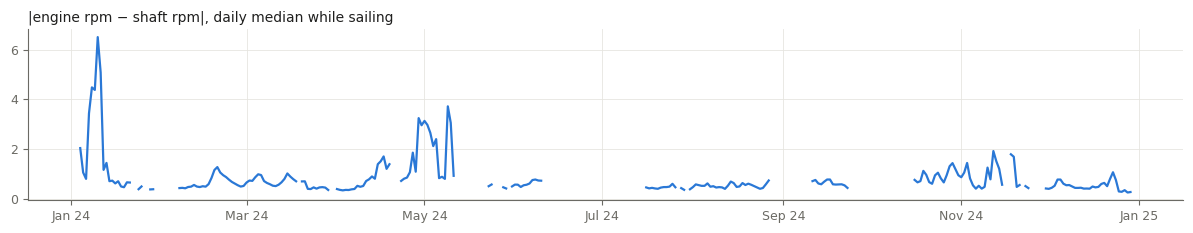

In [14]:
both = running & (w.shaft_rpm > 50) & (w.me_rpm > 50)
diff = (w.me_rpm - w.shaft_rpm)[both]
print(f"engine − shaft rpm: median {diff.median():.2f}, p1 {diff.quantile(.01):.2f}, p99 {diff.quantile(.99):.2f}")
print(f"moments with |difference| > 3 rpm: {(diff.abs() > 3).sum():,} of {len(diff):,}")
dd = T.daily(diff.abs(), "median")
fig, ax = plt.subplots(figsize=(12, 2.4))
ax.plot(dd.index, dd, color=BLUE, linewidth=1.6)
ax.set_title("|engine rpm − shaft rpm|, daily median while sailing", loc="left", color=INK); month_axis(ax)
fig.tight_layout(); plt.show()

### 6c. Signs: rpm and power must agree

Ahead: both positive. Astern: both negative. But "both negative" is only real astern if the **engine** also runs astern; otherwise it is the sign fault from §2. The left plot uses **shaft** rpm, the right plot uses **engine** rpm: the line at 0 kW (torquemeter dropouts) and the mirrored cloud below zero (sign fault) only appear against engine rpm.

,moments,hours,first,last,days
group,,,,,
"ahead: shaft +, power +",1260466,5251.9,2024-01-04 01:56:00,2024-12-29 07:56:00,259
"real astern: engine −, shaft −",722,3.0,2024-01-04 06:17:30,2024-12-29 08:13:30,36
"sign fault: engine +, shaft −",29415,122.6,2024-01-08 08:11:45,2024-12-29 07:58:45,53
"rpm +, power − (sign mismatch)",2,0.0,2024-01-30 21:38:45,2024-11-15 02:08:00,2
"rpm −, power + (sign mismatch)",1,0.0,2024-05-28 22:10:15,2024-05-28 22:10:15,1


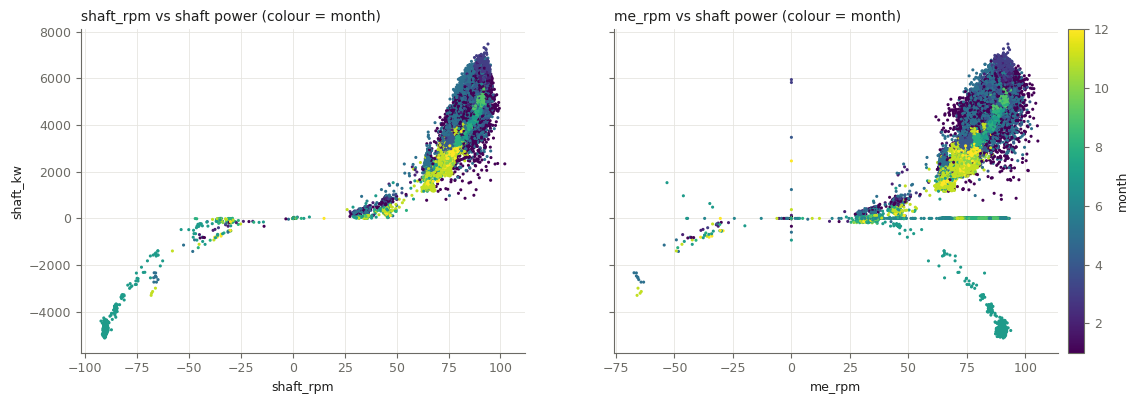

In [15]:
d = w[["shaft_rpm", "me_rpm", "shaft_kw"]].dropna()
groups = {
    "ahead: shaft +, power +": (d.shaft_rpm > 5) & (d.shaft_kw > 0),
    "real astern: engine −, shaft −": (d.shaft_rpm < -5) & (d.me_rpm < -5),
    "sign fault: engine +, shaft −": (d.shaft_rpm < -5) & (d.me_rpm > 5),
    "rpm +, power − (sign mismatch)": (d.shaft_rpm > 5) & (d.shaft_kw < -100),
    "rpm −, power + (sign mismatch)": (d.shaft_rpm < -5) & (d.shaft_kw > 100),
}
rows = []
for name, m in groups.items():
    rows.append({"group": name, "moments": int(m.sum()), "hours": round(hours(m.sum()), 1),
                 "first": d.index[m].min(), "last": d.index[m].max(),
                 "days": int(pd.Series(d.index[m].normalize()).nunique())})
display(pd.DataFrame(rows).set_index("group"))

sample = d.sample(min(len(d), 150_000), random_state=0)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, col in zip(axes, ["shaft_rpm", "me_rpm"]):
    sc = ax.scatter(sample[col], sample.shaft_kw, c=sample.index.month, s=1.5, cmap="viridis", rasterized=True)
    ax.set_xlabel(col); ax.set_title(f"{col} vs shaft power (colour = month)", loc="left", color=INK)
axes[0].set_ylabel("shaft_kw")
fig.colorbar(sc, ax=axes, fraction=0.02, pad=0.01, label="month")
plt.show()

In [16]:
wrong = groups["rpm +, power − (sign mismatch)"] | groups["rpm −, power + (sign mismatch)"]
print(f"Moments where shaft rpm and power disagree in sign: {int(wrong.sum())} (negligible); "
      f"the real sign problem is the engine-vs-shaft fault in §2")

Moments where shaft rpm and power disagree in sign: 3 (negligible); the real sign problem is the engine-vs-shaft fault in §2


### 6d. Fuel per kWh (SFOC) over time

Fuel flow divided by shaft power should stay roughly **flat**: the engine's efficiency changes slowly. A **step** means the power sensor or the fuel meter changed. Only moments sailing with the engine running and power above 2,000 kW are used.

,from,to,days,median,change_vs_previous_%
0,2024-01-04,2024-07-18,130,203.1,NaN
1,2024-07-19,2024-09-23,50,260.3,28.2
2,2024-10-16,2024-12-27,63,332.3,27.7


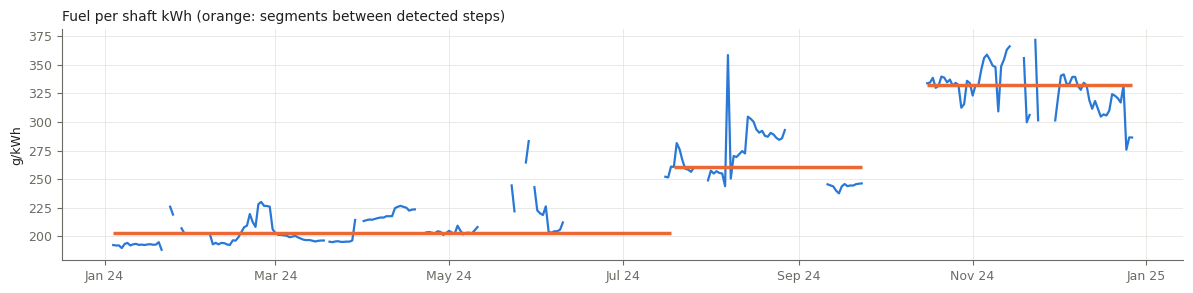

In [17]:
ok = running & (w.shaft_kw > 2000) & (w.fo_kgh > 200)
sfoc = (1000 * w.fo_kgh / w.shaft_kw).where(ok)
sd = T.daily(sfoc, "median")
steps_sfoc = T.find_steps(sd)
display(steps_sfoc.round(1))

fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(sd.index, sd, color=BLUE, linewidth=1.6, label="daily median")
for _, s in steps_sfoc.iterrows():
    ax.hlines(s["median"], pd.Timestamp(s["from"]), pd.Timestamp(s["to"]), color=ORANGE, linewidth=2.5)
ax.set_ylabel("g/kWh"); ax.set_title("Fuel per shaft kWh (orange: segments between detected steps)", loc="left", color=INK)
month_axis(ax); fig.tight_layout(); plt.show()

In [18]:
base = steps_sfoc["median"].iloc[0]
for _, s in steps_sfoc.iloc[1:].iterrows():
    print(f"{s['from']} – {s['to']}: SFOC {s['median']:.0f} g/kWh = {100 * (s['median'] / base - 1):+.0f} % vs first segment")
print("\nA step in SFOC says fuel OR power changed, not which one. §6i compares with references that use only one of them.")

2024-07-19 – 2024-09-23: SFOC 260 g/kWh = +28 % vs first segment
2024-10-16 – 2024-12-27: SFOC 332 g/kWh = +64 % vs first segment

A step in SFOC says fuel OR power changed, not which one. §6i compares with references that use only one of them.


### 6e. Power vs rpm³ (propeller law)

For a fixed-pitch propeller, power ≈ k · rpm³. `k` depends on loading (draft) and on fouling, so it is split by laden and ballast (noon-report displacement above 55,000 t = laden). A slow rise is expected from fouling; a **sudden** step points to the sensor.

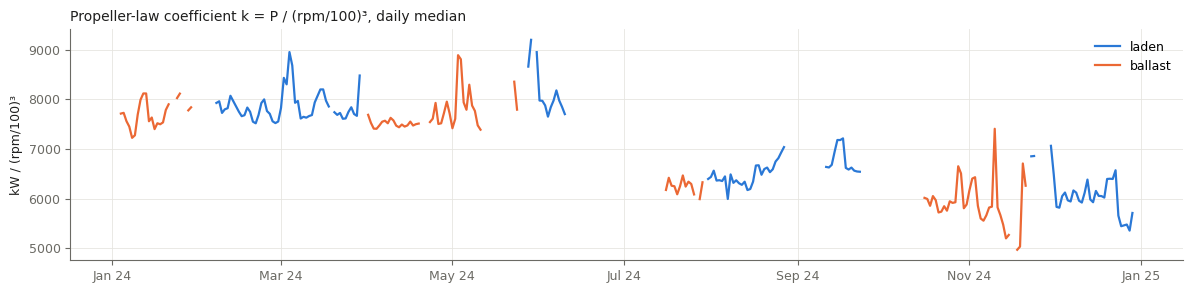

In [19]:
noon = T.load_noon()
disp = noon.Displacement.reindex(w.index.normalize()).values
laden = pd.Series(disp > 55000, index=w.index)
ok = running & (w.shaft_rpm > 60) & (w.shaft_kw > 1000)
k = (w.shaft_kw / (w.shaft_rpm / 100) ** 3).where(ok)
fig, ax = plt.subplots(figsize=(12, 3))
for lab, m, c in [("laden", laden, BLUE), ("ballast", ~laden, ORANGE)]:
    kd = T.daily(k.where(m), "median")
    ax.plot(kd.index, kd, color=c, linewidth=1.6, label=lab)
ax.set_ylabel("kW / (rpm/100)³"); ax.legend(frameon=False)
ax.set_title("Propeller-law coefficient k = P / (rpm/100)³, daily median", loc="left", color=INK)
month_axis(ax); fig.tight_layout(); plt.show()

### 6f. Thrust vs power

Physics (towing-tank resistance ÷ (1 − thrust deduction)) gives roughly **700–900 kN** thrust at 5.7 MW and 12.8 kn.

In [20]:
ok = running & w.shaft_kw.between(4000, 6000) & (w.shaft_rpm > 70) & (w.index < "2024-07-10")
th = w.loc[ok, "thrust_kn"]
print(f"logged thrust at 4–6 MW (before July): median {th.median():,.0f} 'kN' "
      f"(expected about +700 to +900 kN) → factor {abs(th.median()) / 800:.1f}, sign {'negative' if th.median() < 0 else 'positive'}")
tr = T.daily((-w.thrust_kn / w.shaft_kw).where(running & (w.shaft_kw > 2000)), "median")
steps_thrust = T.find_steps(tr)
display(steps_thrust.round(3))
F.add("`thrust_kn`", "all year", "sign or unit",
      f"Logged thrust about {th.median():,.0f} 'kN' where physics gives +700 to +900 kN: negative and about "
      f"{abs(th.median()) / 800:.0f}× too large. Unit or calibration unknown", "§6f", "all readings",
      "Absolute thrust unusable", "Use only as a relative signal, or not at all")

logged thrust at 4–6 MW (before July): median -9,172 'kN' (expected about +700 to +900 kN) → factor 11.5, sign negative


,from,to,days,median,change_vs_previous_%
0,2024-01-04,2024-03-25,70,1.558,NaN
1,2024-03-26,2024-09-23,110,2.049,31.547
2,2024-10-16,2024-12-27,63,3.621,76.743


### 6g. Counters vs rates

`shaft_kwh` (energy counter) should increase by the integral of `shaft_kw`; `shaft_revs` by the integral of `shaft_rpm`. Compared per hour while sailing.

In [21]:
hr = pd.DataFrame({
    "kwh_counter": w.shaft_kwh.resample("1h").last().diff(),
    "kwh_from_power": (w.shaft_kw.clip(lower=0) * 15 / 3600).resample("1h").sum(min_count=200),
    "revs_counter": w.shaft_revs.resample("1h").last().diff(),
    "revs_from_rpm": (w.shaft_rpm.clip(lower=0) * 15 / 60).resample("1h").sum(min_count=200),
    "sailing": running.resample("1h").mean() > 0.95,
})
s = hr[hr.sailing & (hr.kwh_from_power > 1000)]
print(f"energy counter / integrated power: median {(s.kwh_counter / s.kwh_from_power).median():.3f} over {len(s):,} hours")
print(f"revolution counter / integrated rpm: median {(s.revs_counter / s.revs_from_rpm).median():.3f}")
dec = w.shaft_kwh.dropna().diff()
drops = dec[dec < 0]
print(f"\nenergy counter decreases: {len(drops)}")
display(pd.DataFrame({"time": drops.index, "drop_kwh": drops.values}).round(0))
revs_scale = (s.revs_counter / s.revs_from_rpm).median()
F.add("`shaft_revs`", "all year", "sign or unit",
      f"Revolution counter rises {revs_scale:.1f}× faster than integrated shaft rpm: counts 1/60 revolution (or rpm-seconds), "
      "not revolutions. Unit not given in the metadata", "§6g", "all readings", "Wrong if read as revolutions",
      f"Divide by {revs_scale:.0f}, or don't use")
F.add("`shaft_kwh`", ", ".join(str(t_.date()) for t_ in drops.index), "other",
      f"Energy counter goes down {len(drops)} times (largest {drops.min():,.0f} kWh on {drops.idxmin().date()}); "
      f"otherwise it matches integrated power ({(s.kwh_counter / s.kwh_from_power).median():.3f})", "§6g",
      f"{len(drops)} steps", "Wrong if energy is computed from counter differences", "Treat a decrease as a counter reset")

energy counter / integrated power: median 0.999 over 5,183 hours
revolution counter / integrated rpm: median 59.946

energy counter decreases: 8


,time,drop_kwh
0,2024-01-13 12:42:30,-4032.0
1,2024-01-21 04:13:15,-2984.0
2,2024-02-14 18:17:00,-1088.0
3,2024-02-24 09:25:45,-3936.0
4,2024-03-01 14:44:15,-1680.0
5,2024-03-20 10:00:15,-277624.0
6,2024-05-26 10:29:30,-80.0
7,2024-08-27 20:21:45,-272.0


### 6h. Engine sensors vs fuel

Engine load, scavenge air pressure and turbocharger speed all rise with fuel flow. Ratios should be stable; a step means one of them changed (Entry 10 in the challenge suspected the turbocharger or the fuel mass-flow meter).

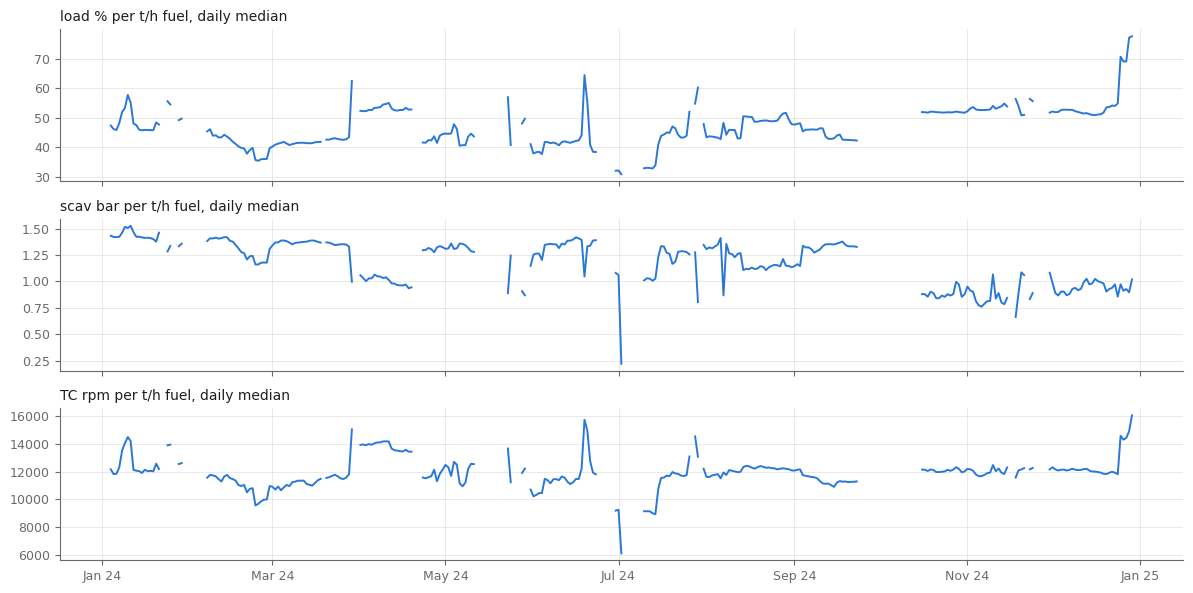

load % per t/h fuel


,from,to,days,median,change_vs_previous_%
0,2024-01-04,2024-10-18,220,43.87,NaN
1,2024-10-19,2024-12-20,55,52.07,18.69
2,2024-12-21,2024-12-29,9,69.03,32.58


scav bar per t/h fuel


,from,to,days,median,change_vs_previous_%
0,2024-01-04,2024-03-25,70,1.38,NaN
1,2024-03-26,2024-09-21,145,1.27,-7.49
2,2024-09-22,2024-12-29,69,0.90,-29.16


TC rpm per t/h fuel


,from,to,days,median,change_vs_previous_%
0,2024-01-04,2024-02-08,25,12169.06,NaN
1,2024-02-09,2024-03-25,45,11190.51,-8.04
2,2024-03-26,2024-04-24,25,13664.71,22.11
3,2024-04-25,2024-06-23,45,11599.39,-15.11
4,2024-06-30,2024-07-16,10,9144.67,-21.16
5,2024-07-17,2024-12-29,134,12052.66,31.80


In [22]:
ok = running & (w.fo_kgh > 500)
eng = {
    "load % per t/h fuel": (w.me_load_pct / (w.fo_kgh / 1000)).where(ok),
    "scav bar per t/h fuel": (w.me_scav_bar / (w.fo_kgh / 1000)).where(ok),
    "TC rpm per t/h fuel": (w.me_tc_rpm_tr / (w.fo_kgh / 1000)).where(ok),
}
fig, axes = plt.subplots(len(eng), 1, figsize=(12, 6), sharex=True)
eng_steps = {}
for ax, (name, s) in zip(axes, eng.items()):
    d = T.daily(s, "median")
    ax.plot(d.index, d, color=BLUE, linewidth=1.4); ax.set_title(name + ", daily median", loc="left", color=INK)
    eng_steps[name] = T.find_steps(d)
month_axis(axes[-1]); fig.tight_layout(); plt.show()
for name, st in eng_steps.items():
    print(name); display(st.round(2))

### 6i. Which sensor stepped: power or fuel?

SFOC (fuel ÷ power) cannot tell which of the two changed. Compare ratios that use **only one** of them:

| Reference | Uses | If **power** reads low | If **fuel** reads high |
|---|---|---|---|
| SFOC = fuel / power | both | up | up |
| propeller-law k = power / rpm³ | power only | **down** | unchanged |
| scavenge air pressure / fuel | fuel only | unchanged | **down** |
| turbocharger rpm / fuel | fuel only | unchanged | **down** |

Fouling can only **raise** k (a heavier hull needs more power at the same rpm), so a drop in k cannot be fouling. **But a hull cleaning lowers k**, and the July drop comes right after a two-week port stay (DQ-12). Fuel per kWh separates the two: a cleaning lowers fuel and power together (SFOC stays flat), a sensor reading low only lowers power (SFOC jumps). So the step is a sensor problem if SFOC jumps, and the k numbers below are an upper bound for the sensor part if a cleaning also happened. Levels are compared in three periods split at the detected SFOC steps; k is compared within laden and within ballast separately.

In [23]:
cuts = [pd.Timestamp(x_) for x_ in steps_sfoc["from"]] + [pd.Timestamp("2025-01-01")]
periods = [(cuts[i_], cuts[i_ + 1]) for i_ in range(len(cuts) - 1)]
labels_ = [f"{a_.date()} – {(b_ - pd.Timedelta(days=1)).date()}" for a_, b_ in periods]
refs = {
    "SFOC (fuel/power)": sfoc,
    "k laden (power/rpm³)": k.where(laden),
    "k ballast (power/rpm³)": k.where(~laden),
    "scav bar per t/h fuel": eng["scav bar per t/h fuel"],
    "TC rpm per t/h fuel": eng["TC rpm per t/h fuel"],
}
tab = pd.DataFrame({name: [ser.loc[a_:b_ - pd.Timedelta("15s")].median() for a_, b_ in periods] for name, ser in refs.items()},
                   index=labels_).T
chg = tab.div(tab.iloc[:, 0], axis=0).sub(1).mul(100)
print("Median level per period"); display(tab.round(2))
print("Change vs first period (%)"); display(chg.round(1))

Median level per period


,2024-01-04 – 2024-07-18,2024-07-19 – 2024-10-15,2024-10-16 – 2024-12-31
SFOC (fuel/power),202.32,260.61,331.05
k laden (power/rpm³),7830.81,6562.43,6031.32
k ballast (power/rpm³),7588.22,6264.86,5860.59
scav bar per t/h fuel,1.35,1.27,0.90
TC rpm per t/h fuel,11570.48,11865.05,12071.69


Change vs first period (%)


,2024-01-04 – 2024-07-18,2024-07-19 – 2024-10-15,2024-10-16 – 2024-12-31
SFOC (fuel/power),0.0,28.8,63.6
k laden (power/rpm³),0.0,-16.2,-23.0
k ballast (power/rpm³),0.0,-17.4,-22.8
scav bar per t/h fuel,0.0,-5.5,-33.0
TC rpm per t/h fuel,0.0,2.5,4.3


In [24]:
k_jul = chg.loc[["k laden (power/rpm³)", "k ballast (power/rpm³)"]].iloc[:, 1].mean()
k_oct = chg.loc[["k laden (power/rpm³)", "k ballast (power/rpm³)"]].iloc[:, 2].mean() if chg.shape[1] > 2 else np.nan
sc_oct = chg.loc["scav bar per t/h fuel"].iloc[2] if chg.shape[1] > 2 else np.nan
print(f"Step 1 ({labels_[1]}): SFOC {chg.iloc[0, 1]:+.0f} %, k {k_jul:+.0f} %, scav/fuel {chg.loc['scav bar per t/h fuel'].iloc[1]:+.0f} %")
if chg.shape[1] > 2:
    print(f"Step 2 ({labels_[2]}): SFOC {chg.iloc[0, 2]:+.0f} % (vs first period), k {k_oct:+.0f} %, scav/fuel {sc_oct:+.0f} %")
print("\nSplitting SFOC into its two causes: SFOC change = (fuel factor) / (power factor), and k gives the power factor.")
for j_ in range(1, chg.shape[1]):
    kf = 1 + chg.loc[["k laden (power/rpm³)", "k ballast (power/rpm³)"]].iloc[:, j_].mean() / 100
    ff = (1 + chg.iloc[0, j_] / 100) * kf
    print(f"  {labels_[j_]}: power reads {100 * (kf - 1):+.0f} %, fuel reads {100 * (ff - 1):+.0f} % (both vs the first period)")
print("Assumes the true k did not change. Fouling would raise it (power under-read larger than shown), a cleaning would lower it (smaller).")
F.add("`shaft_kw`, `shaft_torque_nm`", f"from {steps_sfoc['from'].iloc[1]}", "drift or bias",
      f"Power reads low after the first step: SFOC {chg.iloc[0, 1]:+.0f} % and the propeller-law coefficient {k_jul:+.0f} % "
      "(fouling can only raise it), while fuel-only ratios stay roughly level. Two independent references agree",
      "§6d, §6i", "all power readings after the step", "Power too low → fouling hidden",
      "Correct power for this period (e.g. fuel-based virtual power fitted before the step)")
if chg.shape[1] > 2:
    F.add("`fo_kgh` (and possibly `shaft_kw`)", f"from {steps_sfoc['from'].iloc[2]} (after the Sep–Oct data gap)", "drift or bias",
          f"Second SFOC step to {chg.iloc[0, 2]:+.0f} % vs the first period, but k changes only {k_oct:+.0f} %, while scavenge "
          f"pressure per fuel falls {sc_oct:+.0f} %: mostly a fuel-meter (or engine) change, not only power",
          "§6d, §6i", "all fuel readings after the gap",
          "A fuel-based power correction would over-correct after October", "Check against noon-report fuel (04_noon_reports)")

Step 1 (2024-07-19 – 2024-10-15): SFOC +29 %, k -17 %, scav/fuel -5 %
Step 2 (2024-10-16 – 2024-12-31): SFOC +64 % (vs first period), k -23 %, scav/fuel -33 %

Splitting SFOC into its two causes: SFOC change = (fuel factor) / (power factor), and k gives the power factor.
  2024-07-19 – 2024-10-15: power reads -17 %, fuel reads +7 % (both vs the first period)
  2024-10-16 – 2024-12-31: power reads -23 %, fuel reads +26 % (both vs the first period)
Assumes the true k did not change. Fouling would raise it (power under-read larger than shown), a cleaning would lower it (smaller).


## 7. Step changes: summary

All detected steps in one table, so the dates can be compared. Steps on the **same date in several ratios** point to the shared sensor.

In [25]:
allsteps = []
for name, st in [("fuel per kWh (SFOC)", steps_sfoc), ("thrust per kW", steps_thrust)] + list(eng_steps.items()):
    for _, s in st.iloc[1:].iterrows():
        allsteps.append({"ratio": name, "step_at": s["from"], "change_%": round(s["change_vs_previous_%"], 1)})
pd.DataFrame(allsteps).sort_values("step_at") if allsteps else "no steps found"

,ratio,step_at,change_%
8,TC rpm per t/h fuel,2024-02-09,-8.0
2,thrust per kW,2024-03-26,31.5
6,scav bar per t/h fuel,2024-03-26,-7.5
9,TC rpm per t/h fuel,2024-03-26,22.1
10,TC rpm per t/h fuel,2024-04-25,-15.1
11,TC rpm per t/h fuel,2024-06-30,-21.2
12,TC rpm per t/h fuel,2024-07-17,31.8
0,fuel per kWh (SFOC),2024-07-19,28.2
7,scav bar per t/h fuel,2024-09-22,-29.2
1,fuel per kWh (SFOC),2024-10-16,27.7


## 8. Findings and trust table

**Trust per signal and month**, while sailing with the engine running:
- **bad:** more than 10 % of moments affected, or a known bias (power and torque after the first SFOC step; thrust always)
- fuel is at least **suspect** after the second SFOC step (§6i)
- **suspect:** 1–10 % affected
- **OK:** under 1 %
- **no data:** no readings

"Affected" = torquemeter zero, sign fault, stuck run, above the hard limit, or spike.

In [26]:
month = w.index.to_period("M")
affected = pd.DataFrame(False, index=w.index, columns=PROP)
for s in PROP:
    for _, r_ in stuck_by[s].iterrows():
        affected.loc[r_.start:r_.end, s] = True
    if s in T.LIMITS:
        affected[s] |= w[s] > T.LIMITS[s][1]
    if s in JUMP:
        affected[s] |= (w[s].diff().abs() > JUMP[s]) & step_ok
for s in ["shaft_rpm", "shaft_kw", "shaft_torque_nm", "thrust_kn"]:
    affected[s] |= tm_zero
for s in ["shaft_rpm", "shaft_kw", "shaft_torque_nm"]:
    affected[s] |= sign_fault
affected["fo_kgh"] |= fuel_hi

share = affected[running].groupby(month[running]).mean() * 100
has = w.loc[running, PROP].notna().groupby(month[running]).mean()
trust = share.apply(lambda col: col.map(lambda x: "bad" if x > 10 else "suspect" if x > 1 else "OK"))
trust = trust.where(has >= 0.05, "no data")
first_step = pd.Period(pd.Timestamp(steps_sfoc["from"].iloc[1]), "M")
for s in ["shaft_kw", "shaft_torque_nm"]:
    late = trust.index >= first_step
    trust.loc[late, s] = trust.loc[late, s].replace({"OK": "bad", "suspect": "bad"})
trust["thrust_kn"] = trust["thrust_kn"].replace({"OK": "bad", "suspect": "bad"})
if len(steps_sfoc) > 2:
    second = pd.Period(pd.Timestamp(steps_sfoc["from"].iloc[2]), "M")
    late2 = trust.index >= second
    trust.loc[late2, "fo_kgh"] = trust.loc[late2, "fo_kgh"].replace({"OK": "suspect"})
print("% of sailing moments affected"); display(share.round(1))
print("Trust"); display(trust)

% of sailing moments affected


,shaft_kw,shaft_rpm,shaft_torque_nm,thrust_kn,shaft_kwh,shaft_revs,fo_kgh,me_rpm,me_load_pct,me_scav_bar,me_tc_rpm_tr
time,,,,,,,,,,,
2024-01,5.0,3.8,6.3,0.0,0.0,0.0,0.0,5.0,6.8,0.0,0.0
2024-02,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2024-03,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2024-04,0.5,0.1,0.7,0.0,0.0,0.0,0.0,1.0,0.9,0.0,0.0
2024-05,3.8,2.9,5.1,0.0,0.0,0.0,0.0,6.0,6.3,0.0,0.0
2024-06,59.5,59.5,59.5,59.5,59.4,59.4,0.0,0.0,0.0,0.0,0.0
2024-07,34.4,34.5,34.4,4.5,34.2,4.5,0.0,0.0,0.0,0.0,0.0
2024-08,14.7,14.7,14.7,14.5,14.5,14.5,0.0,0.0,0.0,0.0,0.0
2024-09,45.3,45.3,45.3,45.2,45.1,45.1,0.0,0.0,0.0,0.0,0.0


Trust


,shaft_kw,shaft_rpm,shaft_torque_nm,thrust_kn,shaft_kwh,shaft_revs,fo_kgh,me_rpm,me_load_pct,me_scav_bar,me_tc_rpm_tr
time,,,,,,,,,,,
2024-01,suspect,suspect,suspect,bad,OK,OK,OK,suspect,suspect,OK,OK
2024-02,OK,OK,OK,bad,OK,OK,OK,OK,OK,OK,OK
2024-03,OK,OK,OK,bad,OK,OK,OK,OK,OK,OK,OK
2024-04,OK,OK,OK,bad,OK,OK,OK,suspect,OK,OK,OK
2024-05,suspect,suspect,suspect,bad,OK,OK,OK,suspect,suspect,OK,OK
2024-06,bad,bad,bad,bad,bad,bad,OK,OK,OK,OK,OK
2024-07,bad,bad,bad,bad,bad,suspect,OK,OK,OK,OK,OK
2024-08,bad,bad,bad,bad,bad,bad,OK,OK,OK,OK,OK
2024-09,bad,bad,bad,bad,bad,bad,OK,OK,OK,OK,OK


In [27]:
F.table()

,signal,period,type,what,evidence,affected,impact,options
0,"`shaft_rpm`, `shaft_kw`, `shaft_torque_nm`",mainly 10–17 Jun and 27 Aug – 9 Sep 2024,missing / gap,Torquemeter reads exactly 0 while the ship sai...,01_propulsion §2,656 h in 44 periods,Zero power while sailing; overlaps the end of ...,Set to NaN; never treat as real power
1,"`shaft_rpm`, `shaft_kw`, `shaft_torque_nm`","53 days, 2024-01-08 – 2024-12-29 (most in 10–1...",sign or unit,"Torquemeter reports astern (negative rpm, powe...",01_propulsion §2,"29,415 moments, 123 h",abs() would be right here but wrong for real a...,Flip the sign only where the engine runs ahead...
2,`fo_kgh`,port / anchor stays,stuck or placeholder value,Fuel flow 303 kg/h (median) while engine and s...,01_propulsion §2,759 h,Counted as consumption if summed,Use fuel only when the engine turns; ask what ...
3,`fo_kgh`,"2024-01-29, 2024-02-05, 2024-05-20, 2024-06-27...",out of range,"Fuel flow up to 4,153 kg/h, above the 2,000 kg...",01_propulsion §4,47 readings,Fuel spikes distort daily sums,Set to NaN
4,`thrust_kn`,all year,sign or unit,"Logged thrust about -9,172 'kN' where physics ...",01_propulsion §6f,all readings,Absolute thrust unusable,"Use only as a relative signal, or not at all"
5,`shaft_revs`,all year,sign or unit,Revolution counter rises 59.9× faster than int...,01_propulsion §6g,all readings,Wrong if read as revolutions,"Divide by 60, or don't use"
6,`shaft_kwh`,"2024-01-13, 2024-01-21, 2024-02-14, 2024-02-24...",other,Energy counter goes down 8 times (largest -277...,01_propulsion §6g,8 steps,Wrong if energy is computed from counter diffe...,Treat a decrease as a counter reset
7,"`shaft_kw`, `shaft_torque_nm`",from 2024-07-19,drift or bias,Power reads low after the first step: SFOC +29...,"01_propulsion §6d, §6i",all power readings after the step,Power too low → fouling hidden,Correct power for this period (e.g. fuel-based...
8,`fo_kgh` (and possibly `shaft_kw`),from 2024-10-16 (after the Sep–Oct data gap),drift or bias,"Second SFOC step to +64 % vs the first period,...","01_propulsion §6d, §6i",all fuel readings after the gap,A fuel-based power correction would over-corre...,Check against noon-report fuel (04_noon_reports)


In [28]:
print("Rows for docs/data_quality_log.md (change the DQ numbers to the next free ones):\n")
print(F.markdown_rows(first_id=14))

Rows for docs/data_quality_log.md (change the DQ numbers to the next free ones):

| DQ-14 | `shaft_rpm`, `shaft_kw`, `shaft_torque_nm` | mainly 10–17 Jun and 27 Aug – 9 Sep 2024 | missing / gap | Torquemeter reads exactly 0 while the ship sails (median 10.7 kn) with the engine at 88 rpm and 1126 kg/h fuel: a dropout written as 0 | 01_propulsion §2 | 656 h in 44 periods | Zero power while sailing; overlaps the end of the reference period (June) | Set to NaN; never treat as real power | | open | mp, 22 Oct |
| DQ-15 | `shaft_rpm`, `shaft_kw`, `shaft_torque_nm` | 53 days, 2024-01-08 – 2024-12-29 (most in 10–16 Jul) | sign or unit | Torquemeter reports astern (negative rpm, power, torque) while the engine runs ahead and the ship sails at 13.5 kn. Only 722 moments are real astern (engine also astern) | 01_propulsion §2 | 29,415 moments, 123 h | abs() would be right here but wrong for real astern; 'astern' counts are inflated | Flip the sign only where the engine runs ahead; keep real astern

## Notes

Write your own observations here: what surprised you, what needs a second check, and what to ask the TA.